<center><h1>Yang_Daolong_HW8</h1></center>

Name: Daolong Yang
<br>
Github Username: Dlyang8
<br>
USC ID: 2152334300

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn 
import matplotlib.pyplot as plt
import statsmodels.api as sm
import xgboost
import imblearn
import os
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings
warnings.filterwarnings("ignore")

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [2]:
title = ['ID', "Diagnosis"]
test = []
names = ['radius', 'texture', "perimeter", 'area', 'smoothness', 'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
for i in range(1, 4, 1):
    for j in names:
        naming = j + str(i)
        test.append(naming)
title = title + test
bcw_data = pd.read_csv("Data/wdbc.data", sep = ",", names = title)
bcw_data["Diagnosis"] = bcw_data["Diagnosis"].map({"M": 1, "B": 0})
X = bcw_data.drop(columns=["Diagnosis", 'ID'])
Y = bcw_data['Diagnosis'].copy()

### (b) Monte-Carlo Simulation

In [3]:
montecarlo = 30
scalar = sklearn.preprocessing.StandardScaler()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
def get_results(model, x, y):
    y_pred = model.predict(x)
    y_score = model.decision_function(x)
    return {"accuracy":  accuracy_score(y, y_pred),
        "precision": precision_score(y, y_pred),
        "recall":    recall_score(y, y_pred),
        "f1":        f1_score(y, y_pred),
        "auc":       roc_auc_score(y, y_score),}
def get_roc(model, x_train, y_train, x_test, y_test):
    fig, ax = plt.subplots(figsize=(5, 3))
    sklearn.metrics.RocCurveDisplay.from_estimator(model, x_train, y_train, name="Training", ax=ax)
    sklearn.metrics.RocCurveDisplay.from_estimator(model, x_test, y_test, name="Test", ax=ax)
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
    ax.set_title(f"ROC curve")
    ax.legend()
    return fig, ax
def get_confusion(model, x_train, y_train, x_test, y_test):
    fig, axes = plt.subplots(1, 2, figsize=(5, 2))
    sklearn.metrics.ConfusionMatrixDisplay.from_estimator(model, x_train, y_train, ax=axes[0], cmap="Blues")
    axes[0].set_title(f"Training")
    sklearn.metrics.ConfusionMatrixDisplay.from_estimator(model, x_test, y_test, ax=axes[1], cmap="Blues")
    axes[1].set_title(f"Test")
    plt.tight_layout()
    return fig, axes

#### (i) Supervised Learning

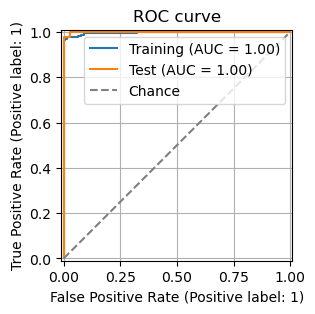

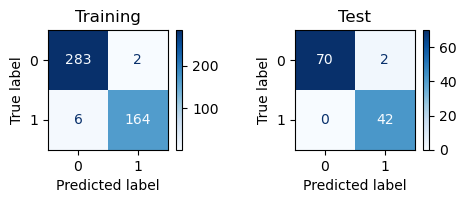

Train Result (mean):
accuracy     0.985568
precision    0.990597
recall       0.970588
f1           0.980473
auc          0.997139
dtype: float64
Test Result (mean):
accuracy     0.969883
precision    0.972334
recall       0.946032
f1           0.958404
auc          0.992714
dtype: float64


In [37]:
train_result = []
test_result = []
for i in range(montecarlo):
    x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, stratify=Y)
    sl_svm = sklearn.svm.LinearSVC(penalty='l1', dual=False, max_iter=10000)
    pipeline = sklearn.pipeline.Pipeline([('scaler', scalar), ('svc', sl_svm)])
    param = {'svc__C': [0.01, 0.1, 1, 10, 100]}
    sl_cv = sklearn.model_selection.GridSearchCV(pipeline, param, cv=5, n_jobs=-1)
    sl_cv.fit(x_train, y_train)
    sl_svm_model = sl_cv.best_estimator_
    train = get_results(sl_svm_model, x_train, y_train)
    train_result.append(train)
    test = get_results(sl_svm_model, x_test, y_test)
    test_result.append(test)
    if i == 25:
        fig, ax = get_roc(sl_svm_model, x_train, y_train, x_test, y_test)
        ax.grid(True)
        plt.show()
        fig, axes = get_confusion(sl_svm_model, x_train, y_train, x_test, y_test)
        axes
        plt.show()
train_result = pd.DataFrame(train_result)
test_result = pd.DataFrame(test_result)
print(f"Train Result (mean):\n{train_result.mean()}")
print(f"Test Result (mean):\n{test_result.mean()}")

#### (ii) Semi-Supervised Learning/ Self-training

##### (A)

In [8]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, stratify=Y)
x_labeled, x_unlabeled, y_labeled, y_unlabeled = sklearn.model_selection.train_test_split(x_train, y_train, test_size=0.5, stratify=y_train)
sml_svm = sklearn.svm.LinearSVC(penalty='l1', dual=False, max_iter=10000)
pipeline = sklearn.pipeline.Pipeline([('scaler', sklearn.preprocessing.StandardScaler()), ('svc', sml_svm)])
param = {'svc__C': [0.01, 0.1, 1, 10, 100]}
sml_cv = sklearn.model_selection.GridSearchCV(pipeline, param, cv=5, n_jobs=-1)
sml_cv.fit(x_labeled, y_labeled)
best_C = sml_cv.best_params_['svc__C']
sml_svm_model = sml_cv.best_estimator_

##### (B)

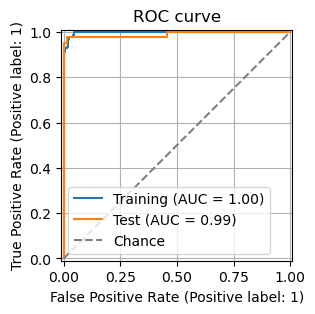

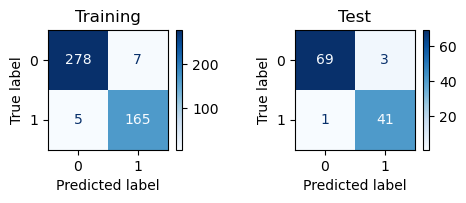

Train Result (mean):
accuracy     0.979707
precision    0.982523
recall       0.962941
f1           0.972551
auc          0.994007
dtype: float64
Test Result (mean):
accuracy     0.958772
precision    0.951172
recall       0.937302
f1           0.943479
auc          0.987213
dtype: float64


In [12]:
train_result, test_result = [], []
for i in range(montecarlo):
    x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, stratify=Y)
    x_labeled, x_unlabeled, y_labeled, y_unlabeled = sklearn.model_selection.train_test_split(x_train, y_train, test_size=0.5, stratify=y_train)
    sml_svm = sklearn.svm.LinearSVC(penalty='l1', dual=False, C=best_C, max_iter=10000)
    sml_svm_model = sklearn.pipeline.Pipeline([('scaler', sklearn.preprocessing.StandardScaler()), ('svc', sml_svm)])
    sml_svm_model.fit(x_labeled, y_labeled)
    length = len(x_unlabeled)
    for j in range(length):
        distance = sml_svm_model.decision_function(x_unlabeled)
        position = int(np.argmax(np.abs(distance)))
        label = x_unlabeled.index[position]
        pred = sml_svm_model.predict(x_unlabeled.loc[[label]])
        x_labeled = pd.concat([x_labeled, x_unlabeled.loc[[label]]])
        y_labeled = pd.concat([y_labeled, pd.Series(pred, index=[label])])
        x_unlabeled = x_unlabeled.drop(label)
        sml_svm = sklearn.svm.LinearSVC(penalty='l1', dual=False, C=best_C, max_iter=10000)
        sml_svm_model = sklearn.pipeline.Pipeline([('scaler', sklearn.preprocessing.StandardScaler()), ('svc', sml_svm)])
        sml_svm_model.fit(x_labeled, y_labeled)
    train_result.append(get_results(sml_svm_model, x_train, y_train))
    test_result.append(get_results(sml_svm_model, x_test, y_test))
    if i == 25:
        fig, ax = get_roc(sml_svm_model, x_train, y_train, x_test, y_test)
        ax.grid(True)
        plt.show()
        fig, axes = get_confusion(sml_svm_model, x_train, y_train, x_test, y_test)
        plt.show()
train_result = pd.DataFrame(train_result)
test_result = pd.DataFrame(test_result)
print(f"Train Result (mean):\n{train_result.mean()}")
print(f"Test Result (mean):\n{test_result.mean()}")

#### (iii) Unsupervised Learning

##### (A)

In [ ]:
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, stratify=Y)
x_train_scaled = sklearn.preprocessing.StandardScaler().fit_transform(x_train)
local_min = []
for i in range(10):
    k_means = sklearn.cluster.KMeans(n_clusters=2, random_state=i, init="random", n_init=1)
    k_means.fit(x_train_scaled)
    inertia = round(k_means.inertia_, 4)
    local_min.append(inertia)

To verify that it reached the global minimum and not the local minimum, I compare the intertia results, if most runs end with similar inertia then I have most likely reached the global minimum, otherwise it likely reached a local minima. 

##### (B) & (C)

In [42]:
def kmeans_getScore(y_pred, y_true, y_score=None):
    auc_input = y_score if y_score is not None else y_pred
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall":    recall_score(y_true, y_pred),
            "f1":        f1_score(y_true, y_pred),
            "auc":       roc_auc_score(y_true, auc_input)}

def kmeans_getRoc(y_score, y_true, name):
    fig, ax = plt.subplots(figsize=(5, 3))
    sklearn.metrics.RocCurveDisplay.from_predictions(y_true, y_score, name=f"K-means ({name})", ax=ax)
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
    ax.set_title(f"ROC curve: {name.upper()}")
    ax.legend()
    return fig, ax

def kmeans_getConfusion(y_pred, y_true, name):
    fig, ax = plt.subplots(figsize=(5, 2))
    sklearn.metrics.ConfusionMatrixDisplay.from_predictions(y_true, y_pred, ax=ax, cmap="Blues")
    ax.set_title(f"Confusion matrix: {name.upper()}")
    plt.tight_layout()
    return fig, ax


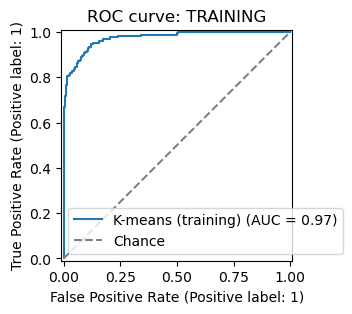

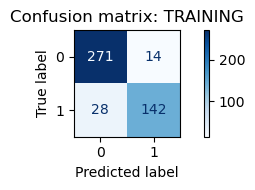

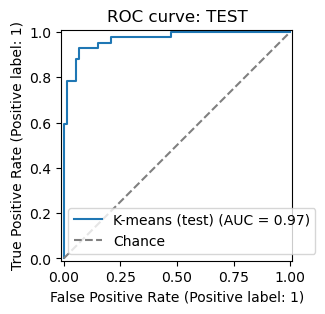

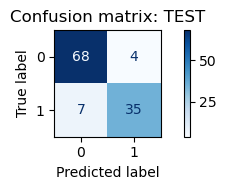

Training Results
accuracy     0.9100
precision    0.9234
recall       0.8282
f1           0.8731
auc          0.9748
Test Results
accuracy     0.9058
precision    0.9090
recall       0.8286
f1           0.8658
auc          0.9717


In [43]:
train_scores = []
test_scores = []

for i in range(montecarlo):
    x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=i)
    k_means = sklearn.pipeline.Pipeline([("scaler", scalar),("kmeans", sklearn.cluster.KMeans(n_clusters=2, random_state=i, init="random", n_init=1))])
    n_clusters = k_means.named_steps["kmeans"].n_clusters
    result = k_means.fit_predict(x_train)
    distances = k_means.transform(x_train)
    closest_30 = {}
    for cluster_id in range(n_clusters):
        closest_30[cluster_id] = np.argsort(distances[:, cluster_id])[:30]
    cluster_to_label = {}
    for k, v in closest_30.items():
        cluster_to_label[k] = y_train.iloc[v].mode()[0]
    if cluster_to_label[0] == cluster_to_label[1]:
        cluster_to_label[1] = 1 - cluster_to_label[0]
    label_to_cluster = {lab: c for c, lab in cluster_to_label.items()}
    y_pred_train = np.zeros_like(result)
    for cluster_ids in range(n_clusters):
        y_pred_train[result == cluster_ids] = cluster_to_label[cluster_ids]
    y_score_train = distances[:, label_to_cluster[0]] - distances[:, label_to_cluster[1]]
    train_scores.append(kmeans_getScore(y_pred_train, y_train, y_score_train))
    result_test = k_means.predict(x_test)
    distances_test = k_means.transform(x_test)
    y_pred_test = np.zeros_like(result_test)
    for cluster_ids in range(n_clusters):
        y_pred_test[result_test == cluster_ids] = cluster_to_label[cluster_ids]
    y_score_test = distances_test[:, label_to_cluster[0]] - distances_test[:, label_to_cluster[1]]
    test_scores.append(kmeans_getScore(y_pred_test, y_test, y_score_test))
    if i == 25:
        kmeans_getRoc(y_score_train, y_train, "training")
        kmeans_getConfusion(y_pred_train, y_train, "training")
        kmeans_getRoc(y_score_test, y_test, "test")
        kmeans_getConfusion(y_pred_test, y_test, "test")
        plt.show()
train_df = pd.DataFrame(train_scores)
test_df = pd.DataFrame(test_scores)
print("Training Results")
print(train_df.mean().round(4).to_string())
print("Test Results")
print(test_df.mean().round(4).to_string())

#### (iv) Spectral Clustering

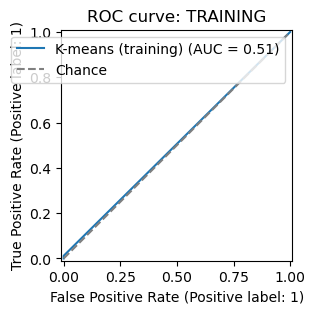

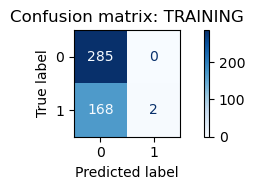

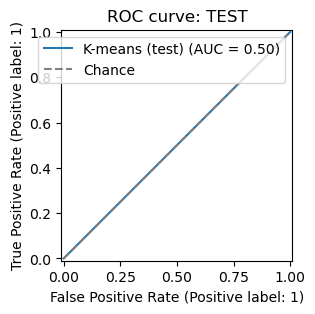

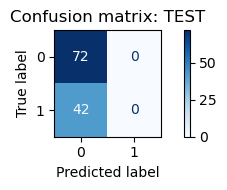

Training Results
accuracy     0.6300
precision    1.0000
recall       0.0096
f1           0.0190
auc          0.5048
Test Results
accuracy     0.6348
precision    0.3667
recall       0.0087
f1           0.0171
auc          0.5044


In [44]:
train_scores, test_scores = [], []

for i in range(montecarlo):
    x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=i)
    sc = sklearn.preprocessing.StandardScaler().fit(x_train)
    x_all = np.vstack([sc.transform(x_train), sc.transform(x_test)])
    n_tr = len(x_train)

    sc_model = sklearn.cluster.SpectralClustering(n_clusters=2, affinity="rbf", gamma=1, random_state=i)
    result = sc_model.fit_predict(x_all)
    r_train, r_test = result[:n_tr], result[n_tr:]

    pos_frac = {}
    for k in range(2):
        members = y_train.values[r_train == k]
        pos_frac[k] = members.mean() if len(members) > 0 else 0.0  
    pos_cluster = max(pos_frac, key=pos_frac.get)

    y_pred_train = (r_train == pos_cluster).astype(int)
    y_pred_test  = (r_test  == pos_cluster).astype(int)
    y_score_train = np.array([pos_frac[k] for k in r_train])  
    y_score_test  = np.array([pos_frac[k] for k in r_test])

    train_scores.append(kmeans_getScore(y_pred_train, y_train, y_score_train))
    test_scores.append(kmeans_getScore(y_pred_test, y_test, y_score_test))

    if i == 25:
        kmeans_getRoc(y_score_train, y_train, "training")
        kmeans_getConfusion(y_pred_train, y_train, "training")
        kmeans_getRoc(y_score_test, y_test, "test")
        kmeans_getConfusion(y_pred_test, y_test, "test")
        plt.show()

print("Training Results")
print(pd.DataFrame(train_scores).mean().round(4).to_string())
print("Test Results")
print(pd.DataFrame(test_scores).mean().round(4).to_string())

#### (v) Compare

As expected, supervised learning on the fully labeled training set performs best. Semi-supervised self-training with only half the labels comes very close, mainly losing some recall, because some self-assigned labels are wrong. K-means, which never sees labels except for the 30-point majority poll, is clearly worse, especially in recall. Spectral clustering with γ = 1 performs at chance level: with 30 standardized features, the RBF affinities are almost all zero, so it splits off a few outliers instead of separating the two classes.

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

In [45]:
columns_bank = ['variance', 'skewness', 'curtosis', 'entropy', 'class']
banknote_data = pd.read_csv("Data/data_banknote_authentication.txt",sep = ',',names = columns_bank)
X = banknote_data.drop(columns='class')
Y = banknote_data[['class']].copy()
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(X, Y, train_size = 900, test_size = 472, stratify=Y)

### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

In [48]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()
pool = list(range(10, 910, 10))
pl_test_error = []
for i in range(50):
    pool_idx = list(y_train.groupby(y_train).sample(n=5).index)
    remaining = x_train.index.drop(pool_idx)
    for k, j in enumerate(pool):
        if k > 0:
            new_idx = x_train.loc[remaining].sample(n=10).index
            pool_idx.extend(new_idx)
            remaining = remaining.drop(new_idx)
        x_pool = x_train.loc[pool_idx]
        y_pool = y_train.loc[pool_idx]
        pipeline = sklearn.pipeline.Pipeline([('scaler', sklearn.preprocessing.StandardScaler()),('svm', sklearn.svm.LinearSVC(penalty='l1', dual=False, max_iter=100000)),])
        parameter = {'svm__C': [0.01, 0.1, 1, 10]}
        pl_cv = sklearn.model_selection.GridSearchCV(pipeline, parameter, cv=5, n_jobs=-1)
        pl_cv.fit(x_pool, y_pool)
        test_error = 1 - pl_cv.score(x_test, y_test)
        pl_test_error.append(test_error)

#### (ii) Active

In [49]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()
pool = list(range(10, 910, 10))
al_test_error = []
for i in range(50):
    pool_idx = list(y_train.groupby(y_train).sample(n=5).index)
    remaining = x_train.index.drop(pool_idx)

    for j in pool:
        x_pool = x_train.loc[pool_idx]
        y_pool = y_train.loc[pool_idx]

        pipeline = sklearn.pipeline.Pipeline([('scaler', sklearn.preprocessing.StandardScaler()),('svm', sklearn.svm.LinearSVC(penalty='l1', dual=False, max_iter=100000)),])
        parameter = {'svm__C': [0.01, 0.1, 1, 10]}
        al_cv = sklearn.model_selection.GridSearchCV(pipeline, parameter, cv=5, n_jobs=-1)
        al_cv.fit(x_pool, y_pool)
        test_error = 1 - al_cv.score(x_test, y_test)
        al_test_error.append(test_error)
        if len(remaining) > 0:
            distances = abs(al_cv.decision_function(x_train.loc[remaining]))
            new_idx = remaining[distances.argsort()[:10]]
            pool_idx.extend(new_idx)
            remaining = remaining.drop(new_idx)

### (c) Average the 50 test errors

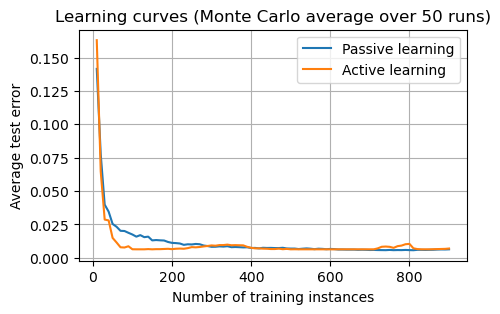

In [50]:
pl_avg_error = np.array(pl_test_error).reshape(50, 90).mean(axis=0)
al_avg_error = np.array(al_test_error).reshape(50, 90).mean(axis=0)

plt.figure(figsize=(5, 3))
plt.plot(pool, pl_avg_error, label='Passive learning')
plt.plot(pool, al_avg_error, label='Active learning')
plt.xlabel('Number of training instances')
plt.ylabel('Average test error')
plt.title('Learning curves (Monte Carlo average over 50 runs)')
plt.legend()
plt.grid(True)
plt.show()